# APS graph 

In [1]:
import pandas as pd 
from pathlib import Path
import igraph as ig
import seaborn as sns
import matplotlib.pyplot as plt
from rich.progress import track
import ast
from tqdm.auto import tqdm
import ujson as json
import dask.dataframe as ddf
from dask.distributed import Client, LocalCluster


tqdm.pandas()

In [2]:
basepath: Path = Path('/N/project/openalex')
processed_dir = basepath / 'ssikdar' / 'processed'
aps_path = basepath / 'APS' / 'csvs'

In [9]:
cluster = LocalCluster(n_workers=5, memory_limit='20GB')
client = Client(cluster)
client

distributed.diskutils - INFO - Found stale lock file and directory '/N/slate/ssikdar/py-temp/openalex/notebooks/dask-worker-space/worker-j6lm88vd', purging
distributed.diskutils - INFO - Found stale lock file and directory '/N/slate/ssikdar/py-temp/openalex/notebooks/dask-worker-space/worker-chatvoii', purging
distributed.diskutils - INFO - Found stale lock file and directory '/N/slate/ssikdar/py-temp/openalex/notebooks/dask-worker-space/worker-8_h65hx9', purging
distributed.diskutils - INFO - Found stale lock file and directory '/N/slate/ssikdar/py-temp/openalex/notebooks/dask-worker-space/worker-79pdrr3b', purging
distributed.diskutils - INFO - Found stale lock file and directory '/N/slate/ssikdar/py-temp/openalex/notebooks/dask-worker-space/worker-1nga5dxe', purging


Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: http://127.0.0.1:8787/status,
Dashboard: http://127.0.0.1:8787/status,Workers: 5
Total threads: 5,Total memory: 93.13 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:37091,Workers: 5
Dashboard: http://127.0.0.1:8787/status,Total threads: 5
Started: Just now,Total memory: 93.13 GiB
Comm: tcp://127.0.0.1:44539,Total threads: 1
Dashboard: http://127.0.0.1:41705/status,Memory: 18.63 GiB
Nanny: tcp://127.0.0.1:33271,


distributed.utils - ERROR - 'start'
Traceback (most recent call last):
  File "/N/u/ssikdar/Carbonate/.conda/envs/scisci/lib/python3.8/site-packages/distributed/utils.py", line 693, in log_errors
    yield
  File "/N/u/ssikdar/Carbonate/.conda/envs/scisci/lib/python3.8/site-packages/distributed/dashboard/components/shared.py", line 285, in update
    ts = metadata["keys"][self.key]
KeyError: 'start'
tornado.application - ERROR - Exception in callback functools.partial(<bound method IOLoop._discard_future_result of <zmq.eventloop.ioloop.ZMQIOLoop object at 0x2b1b0f3606a0>>, <Task finished name='Task-861' coro=<_needs_document_lock.<locals>._needs_document_lock_wrapper() done, defined at /N/u/ssikdar/Carbonate/.conda/envs/scisci/lib/python3.8/site-packages/bokeh/server/session.py:77> exception=KeyError('start')>)
Traceback (most recent call last):
  File "/N/u/ssikdar/Carbonate/.conda/envs/scisci/lib/python3.8/site-packages/tornado/ioloop.py", line 741, in _run_callback
    ret = callbac

## Util functions

In [4]:
def read_parquet(path, **args):
    df = pd.read_parquet(path, engine='pyarrow', **args)
    df.reset_index(inplace=True)
    if '__null_dask_index__' in df.columns:
        df.drop(['__null_dask_index__'], axis=1, inplace=True)
    df.drop_duplicates(inplace=True)
    print(f'Read {len(df):,} rows from {path.stem!r}')
    return df 

def read_csv(path, **args):
    df = pd.read_csv(path, **args)
    df.drop_duplicates(inplace=True)
    print(f'Read {len(df):,} rows from {path.stem!r}')
    return df 

def to_parquet(df, path, **args):
    print(f'Writing {len(df):,} rows to {path.stem!r}')
    df.to_parquet(path, engine='pyarrow', index=False, **args)
    return

def construct_abstracts(inv_abstracts):
    """"
    Construct abstracts from inverted index
    keys: words, values: list of locations
    """
    abstracts = []
    
    for inv_abstract_st in tqdm(inv_abstracts, desc='Constructing abstracts..'):
        inv_abstract_st = ast.literal_eval(inv_abstract_st)  # convert to python object
        if isinstance(inv_abstract_st, bytes):
            inv_abstract_st = inv_abstract_st.decode('utf-8', errors='replace')
        
        inv_abstract = json.loads(inv_abstract_st) if isinstance(inv_abstract_st, str) else inv_abstract_st
        abstract_dict = {}
        for word, locs in inv_abstract.items():  # invert the inversion
            for loc in locs:
                abstract_dict[loc] = word
        abstract = ' '.join(map(lambda x: x[1], # pick the words
                            sorted(abstract_dict.items())))  # sort abstract dictionary by indices
        if len(abstract) == 0:
            abstract = None
        abstracts.append(abstract)
    return abstracts

In [5]:
aps_works_df = `read_csv(path=processed_dir / 'APS/cleaned/csvs' / 'works.csv.gz')
aps_works_df

Read 688,288 rows from 'works.csv'


,work_id,venue_id,venue_name,doi,title,publication_year,publication_date,type,abstract
0,https://openalex.org/W2945786111,https://openalex.org/V6791298,Physical Review B,NaN,Comment on Field emission as a probe of the su...,1976,1976-07-15,journal-article,NaN
1,https://openalex.org/W2254473369,https://openalex.org/V6791298,Physical Review B,NaN,Magnetic Behavior of Kondo-Lattice System CeRu...,1983,1983-01-01,journal-article,NaN
2,https://openalex.org/W2782019466,https://openalex.org/V6791298,Physical Review B,NaN,Spectroscopy and electronic structure of Sr2YR...,2016,2016-01-01,journal-article,NaN
3,https://openalex.org/W1612831857,https://openalex.org/V6791298,Physical Review B,https://doi.org/10.1103/physrevb.37.2618,Metallic CaSi2 epitaxial films on Si(111).,1988,1988-02-15,journal-article,NaN
4,https://openalex.org/W1615049408,https://openalex.org/V6791298,Physical Review B,https://doi.org/10.1103/physrevb.71.134425,Anomalous Hall effects in amorphousNi74Mn24Pt2...,2005,2005-04-29,journal-article,NaN
...,...,...,...,...,...,...,...,...,...
688283,https://openalex.org/W4206764813,https://openalex.org/V4210235286,Physical Review,https://doi.org/10.1103/physreve.104.064135,Microemulsions in the driven Widom-Rowlinson l...,2021,2021-12-27,journal-article,An investigation of the two-dimensional Widom-...
688284,https://openalex.org/W4211033296,https://openalex.org/V4210208989,Physical Review,https://doi.org/10.1103/physrevb.16.4853,Shunted-Josephson-junction model. I. The auton...,1977,1977-12-01,journal-article,NaN
688285,https://openalex.org/W4210957530,https://openalex.org/V4210208989,Physical Review,https://doi.org/10.1103/physrevb.5.3370.3,Optical Properties of Single-Crystal Cadmium,1972,1972-04-15,journal-article,NaN
688286,https://openalex.org/W4205808126,https://openalex.org/V4210208989,Physical Review,https://doi.org/10.1103/physrevb.3.3080,Reduction in Page Charges,1971,1971-05-01,journal-article,NaN


In [49]:
aps_works_df = aps_works_df.query('type=="journal-article"')
aps_works_df

,work_id,venue_id,venue_name,doi,title,publication_year,publication_date,type,abstract
0,https://openalex.org/W2945786111,https://openalex.org/V6791298,Physical Review B,NaN,Comment on Field emission as a probe of the su...,1976,1976-07-15,journal-article,NaN
1,https://openalex.org/W2254473369,https://openalex.org/V6791298,Physical Review B,NaN,Magnetic Behavior of Kondo-Lattice System CeRu...,1983,1983-01-01,journal-article,NaN
2,https://openalex.org/W2782019466,https://openalex.org/V6791298,Physical Review B,NaN,Spectroscopy and electronic structure of Sr2YR...,2016,2016-01-01,journal-article,NaN
3,https://openalex.org/W1612831857,https://openalex.org/V6791298,Physical Review B,https://doi.org/10.1103/physrevb.37.2618,Metallic CaSi2 epitaxial films on Si(111).,1988,1988-02-15,journal-article,NaN
4,https://openalex.org/W1615049408,https://openalex.org/V6791298,Physical Review B,https://doi.org/10.1103/physrevb.71.134425,Anomalous Hall effects in amorphousNi74Mn24Pt2...,2005,2005-04-29,journal-article,NaN
...,...,...,...,...,...,...,...,...,...
688968,https://openalex.org/W4206764813,https://openalex.org/V4210235286,Physical Review,https://doi.org/10.1103/physreve.104.064135,Microemulsions in the driven Widom-Rowlinson l...,2021,2021-12-27,journal-article,An investigation of the two-dimensional Widom-...
688969,https://openalex.org/W4211033296,https://openalex.org/V4210208989,Physical Review,https://doi.org/10.1103/physrevb.16.4853,Shunted-Josephson-junction model. I. The auton...,1977,1977-12-01,journal-article,NaN
688970,https://openalex.org/W4210957530,https://openalex.org/V4210208989,Physical Review,https://doi.org/10.1103/physrevb.5.3370.3,Optical Properties of Single-Crystal Cadmium,1972,1972-04-15,journal-article,NaN
688971,https://openalex.org/W4205808126,https://openalex.org/V4210208989,Physical Review,https://doi.org/10.1103/physrevb.3.3080,Reduction in Page Charges,1971,1971-05-01,journal-article,NaN


In [50]:
aps_works_df.to_csv(processed_dir / 'APS' / 'cleaned' / 'csvs' / 'works.csv.gz', index=False)

In [52]:
to_parquet(aps_works_df, path=processed_dir / 'APS' / 'cleaned' / 'parquets' / 'works')

Writing 688,288 rows to 'works'


In [9]:
aps_works_df.query(f'doi.isna()')

,work_id,venue_id,venue_name,doi,title,publication_year,publication_date,type,abstract
0,https://openalex.org/W2945786111,https://openalex.org/V6791298,Physical Review B,NaN,Comment on Field emission as a probe of the su...,1976,1976-07-15,journal-article,NaN
1,https://openalex.org/W2254473369,https://openalex.org/V6791298,Physical Review B,NaN,Magnetic Behavior of Kondo-Lattice System CeRu...,1983,1983-01-01,journal-article,NaN
2,https://openalex.org/W2782019466,https://openalex.org/V6791298,Physical Review B,NaN,Spectroscopy and electronic structure of Sr2YR...,2016,2016-01-01,journal-article,NaN
18,https://openalex.org/W1641535934,https://openalex.org/V6791298,Physical Review B,NaN,Magnetism of Gd5Ge4 from first principles,2007,2007-01-01,journal-article,NaN
23,https://openalex.org/W1660525591,https://openalex.org/V6791298,Physical Review B,NaN,Diffusion of 23Na and 35K in the eutectic melt...,2001,2001-01-01,journal-article,NaN
...,...,...,...,...,...,...,...,...,...
686826,https://openalex.org/W2307843527,https://openalex.org/V137042341,Physical Review X,NaN,Asymmetric Electron Transport at Monolayer-Bil...,2014,2014-01-01,journal-article,The symmetry of the graphene honeycomb lattice...
687218,https://openalex.org/W3141855990,https://openalex.org/V4210238307,Physical Review,NaN,Fully-heavy tetraquarks,2019,2019-01-09,journal-article,NaN
687219,https://openalex.org/W3142981222,https://openalex.org/V4210238307,Physical Review,NaN,Inflation followed by BKL collapse inside accr...,2017,2017-03-06,journal-article,NaN
687220,https://openalex.org/W2768529791,https://openalex.org/V4210238307,Physical Review,NaN,Corrections to Di-Higgs Production with Light ...,2017,2017-11-15,journal-article,The Higgs pair production in gluon fusion is a...


## combine works and work authorships 

In [18]:
authors_df = read_parquet(processed_dir / 'APS' / 'works')
authors_df.head(2)

Read 734,703 rows from 'authors'


,id,orcid,display_name,display_name_alternatives,works_count,cited_by_count,last_known_institution,works_api_url,updated_date
0,https://openalex.org/A3124000883,None,A. Fridman,[],13,307,https://openalex.org/I157614274,https://api.openalex.org/works?filter=author.i...,2021-02-01
1,https://openalex.org/A3035715749,None,B C Choudhary,[],1,0,,https://api.openalex.org/works?filter=author.i...,2020-06-19
2,https://openalex.org/A3026239558,None,TD Bestwick,[],1,5,,https://api.openalex.org/works?filter=author.i...,2020-05-29
3,https://openalex.org/A3032924466,None,Z. C. Yan,[],1,0,,https://api.openalex.org/works?filter=author.i...,2020-06-12
4,https://openalex.org/A3027259930,None,VI Vi Gavrilenko,[],1,21,https://openalex.org/I149899117,https://api.openalex.org/works?filter=author.i...,2020-05-29
...,...,...,...,...,...,...,...,...,...
734698,https://openalex.org/A2636993087,None,R. Fleming,[],2,106,https://openalex.org/I98251732,https://api.openalex.org/works?filter=author.i...,2022-02-17
734699,https://openalex.org/A3208044906,None,H. Breuer,[],1,45,https://openalex.org/I132091411,https://api.openalex.org/works?filter=author.i...,2022-02-17
734700,https://openalex.org/A2621153960,None,Paul Hodgson,[],805,61330,https://openalex.org/I91136226,https://api.openalex.org/works?filter=author.i...,2022-02-17
734701,https://openalex.org/A2621942878,None,Claudine Guthmann,[],18,366,https://openalex.org/I204730241,https://api.openalex.org/works?filter=author.i...,2022-02-17


In [11]:
authorships_df = read_parquet(processed_dir / 'APS' / 'works_authorships')
authorships_df

Read 3,572,537 rows from 'works_authorships'


,work_id,author_position,author_id,institution_id,raw_affiliation_string
0,https://openalex.org/W2809261018,first,https://openalex.org/A2099676161,<NA>,<NA>
1,https://openalex.org/W2809261018,last,https://openalex.org/A2119534751,<NA>,<NA>
2,https://openalex.org/W2945786111,first,https://openalex.org/A2096989079,<NA>,<NA>
3,https://openalex.org/W2254038901,first,https://openalex.org/A2706093076,<NA>,<NA>
4,https://openalex.org/W2254038901,last,https://openalex.org/A3134815417,<NA>,<NA>
...,...,...,...,...,...
3573215,https://openalex.org/W3123145793,last,https://openalex.org/A2790010927,https://openalex.org/I183935753,"Department of Mathematics, King's College Lond..."
3573216,https://openalex.org/W3123145793,last,https://openalex.org/A2790010927,https://openalex.org/I196576671,"Department of Mathematics, King's College Lond..."
3573217,https://openalex.org/W3207785883,first,https://openalex.org/A3167532416,https://openalex.org/I20231570,"School of Physics, Peking University, Beijing ..."
3573218,https://openalex.org/W3207785883,middle,https://openalex.org/A2657232786,https://openalex.org/I19820366,"CAS Key Laboratory of Theoretical Physics, Ins..."


In [64]:
cols = ['work_id', 'title', 'publication_year', 'author_id', 'author_position', 'institution_id']
df = pd.merge(authorships_df, aps_works_df, left_on='work_id', right_on='work_id')[cols]
df = pd.merge(df, authors_df, left_on='author_id', right_on='id')
df.rename({'display_name': 'author_name'}, axis=1, inplace=True)
cols = ['work_id', 'title', 'publication_year', 'author_id', 'author_name', 'author_position', 'institution_id']
auth_df = df[cols]
auth_df

,work_id,title,publication_year,author_id,author_name,author_position,institution_id
0,https://openalex.org/W2945786111,Comment on Field emission as a probe of the su...,1976,https://openalex.org/A2096989079,David R. Penn,first,<NA>
1,https://openalex.org/W2043929483,Electron mean-free-path calculations using a m...,1987,https://openalex.org/A2096989079,David R. Penn,first,https://openalex.org/I1321296531
2,https://openalex.org/W2063105163,Mean free paths of very-low-energy electrons: ...,1980,https://openalex.org/A2096989079,David R. Penn,first,https://openalex.org/I1321296531
3,https://openalex.org/W2000423142,Role of Intrinsic Plasmons in Conduction-Band ...,1978,https://openalex.org/A2096989079,David R. Penn,first,<NA>
4,https://openalex.org/W2082795266,Theory of spin-polarized secondary electrons i...,1985,https://openalex.org/A2096989079,David R. Penn,first,https://openalex.org/I1321296531
...,...,...,...,...,...,...,...
3445199,https://openalex.org/W3207113520,Signature of nonuniform area quantization on g...,2021,https://openalex.org/A3189257609,Kabir Chakravarti,first,https://openalex.org/I27674431
3445200,https://openalex.org/W3134653963,Theory for size segregation in flowing granula...,2021,https://openalex.org/A2727836454,Mohit Nema,middle,https://openalex.org/I94234084
3445201,https://openalex.org/W3134780308,Decomposition of the transition phase in multi...,2021,https://openalex.org/A3036804719,Divya Bharti,first,https://openalex.org/I149899117
3445202,https://openalex.org/W3134780308,Decomposition of the transition phase in multi...,2021,https://openalex.org/A3010336175,Gavin Menning,middle,https://openalex.org/I87213936


In [56]:
inst_df = read_parquet(processed_dir / 'institutions')
inst_df

Read 108,660 rows from 'institutions'


,index,id,ror,display_name,country_code,type,homepage_url,image_url,image_thumbnail_url,display_name_acroynyms,display_name_alternatives,works_count,cited_by_count,works_api_url,updated_date
0,0,https://openalex.org/I9106422,<NA>,Banca Nazionale del Lavoro,IT,<NA>,http://www.bnl.it/,https://upload.wikimedia.org/wikipedia/commons...,https://upload.wikimedia.org/wikipedia/commons...,b'null',b'[]',4,12,https://api.openalex.org/works?filter=institut...,2022-02-02
1,1,https://openalex.org/I107442514,https://ror.org/046hkwj59,Coastal Bend College,US,education,http://coastalbend.edu/,<NA>,<NA>,b'null',"b'[""Bee County College""]'",32,98,https://api.openalex.org/works?filter=institut...,2022-02-02
2,2,https://openalex.org/I134443768,<NA>,Halla Climate Control Corp,<NA>,<NA>,<NA>,<NA>,<NA>,b'null',b'[]',17,140,https://api.openalex.org/works?filter=institut...,2022-02-02
3,3,https://openalex.org/I139770027,https://ror.org/04j80nh06,RUAG,DE,company,http://www.ruag.com/de/konzern/konzern-home/,https://upload.wikimedia.org/wikipedia/commons...,https://upload.wikimedia.org/wikipedia/commons...,b'null',"b'[""R\xc3\xbcstungs Unternehmen Aktiengesellsc...",35,303,https://api.openalex.org/works?filter=institut...,2022-02-02
4,4,https://openalex.org/I140800249,<NA>,Maersk Drilling,DK,<NA>,http://www.maerskdrilling.com/,<NA>,<NA>,b'null',b'[]',25,60,https://api.openalex.org/works?filter=institut...,2022-02-02
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
108655,108655,https://openalex.org/I4210166499,https://ror.org/05vr1c885,Henan Polytechnic University,CN,education,http://www2.hpu.edu.cn/en/,<NA>,<NA>,b'null',b'[]',12952,196133,https://api.openalex.org/works?filter=institut...,2022-02-17
108656,108656,https://openalex.org/I4210166882,https://ror.org/03gbp6p96,Hospital of Prato,IT,healthcare,<NA>,<NA>,<NA>,b'null',b'[]',381,29325,https://api.openalex.org/works?filter=institut...,2022-02-17
108657,108657,https://openalex.org/I4210166892,https://ror.org/04j0szy54,Hôpital Boucicaut,FR,healthcare,<NA>,<NA>,<NA>,b'null',b'[]',383,8587,https://api.openalex.org/works?filter=institut...,2022-02-17
108658,108658,https://openalex.org/I4210167311,https://ror.org/05skxkv18,Institute of Zoology,CN,facility,http://english.ioz.cas.cn/,<NA>,<NA>,b'null',"b'[""Fan Memorial Institute of Biology""]'",1178,41165,https://api.openalex.org/works?filter=institut...,2022-02-17


In [65]:
cols = ['work_id', 'title', 'publication_year', 'author_id', 'author_name', 'author_position', 'institution_id', 'institution_name']
df = pd.merge(auth_df, inst_df, left_on='institution_id', right_on='id', how='left')
df.rename({'display_name': 'institution_name'}, axis=1, inplace=True)
inst_info_df = df[cols]
inst_info_df

,work_id,title,publication_year,author_id,author_name,author_position,institution_id,institution_name
0,https://openalex.org/W2945786111,Comment on Field emission as a probe of the su...,1976,https://openalex.org/A2096989079,David R. Penn,first,<NA>,<NA>
1,https://openalex.org/W2043929483,Electron mean-free-path calculations using a m...,1987,https://openalex.org/A2096989079,David R. Penn,first,https://openalex.org/I1321296531,National Institute of Standards and Technology
2,https://openalex.org/W2063105163,Mean free paths of very-low-energy electrons: ...,1980,https://openalex.org/A2096989079,David R. Penn,first,https://openalex.org/I1321296531,National Institute of Standards and Technology
3,https://openalex.org/W2000423142,Role of Intrinsic Plasmons in Conduction-Band ...,1978,https://openalex.org/A2096989079,David R. Penn,first,<NA>,<NA>
4,https://openalex.org/W2082795266,Theory of spin-polarized secondary electrons i...,1985,https://openalex.org/A2096989079,David R. Penn,first,https://openalex.org/I1321296531,National Institute of Standards and Technology
...,...,...,...,...,...,...,...,...
3445199,https://openalex.org/W3207113520,Signature of nonuniform area quantization on g...,2021,https://openalex.org/A3189257609,Kabir Chakravarti,first,https://openalex.org/I27674431,Indian Institute of Technology Gandhinagar
3445200,https://openalex.org/W3134653963,Theory for size segregation in flowing granula...,2021,https://openalex.org/A2727836454,Mohit Nema,middle,https://openalex.org/I94234084,Indian Institute of Technology Kanpur
3445201,https://openalex.org/W3134780308,Decomposition of the transition phase in multi...,2021,https://openalex.org/A3036804719,Divya Bharti,first,https://openalex.org/I149899117,Max Planck Society
3445202,https://openalex.org/W3134780308,Decomposition of the transition phase in multi...,2021,https://openalex.org/A3010336175,Gavin Menning,middle,https://openalex.org/I87213936,Drake University


In [66]:
inst_info_df.query('author_id=="https://openalex.org/A2122189410"')

,work_id,title,publication_year,author_id,author_name,author_position,institution_id,institution_name
1681871,https://openalex.org/W1988781413,Coevolution of Glauber-like Ising dynamics and...,2009,https://openalex.org/A2122189410,Santo Fortunato,middle,https://openalex.org/I134940468,Institute for Scientific Interchange
1681872,https://openalex.org/W2042048324,Importance of extremists for the structure of ...,2005,https://openalex.org/A2122189410,Santo Fortunato,middle,https://openalex.org/I20121455,Bielefeld University
1681873,https://openalex.org/W1505172586,Network-based model of the growth of termite n...,2015,https://openalex.org/A2122189410,Santo Fortunato,middle,https://openalex.org/I592451,Indiana University
1681874,https://openalex.org/W1505172586,Network-based model of the growth of termite n...,2015,https://openalex.org/A2122189410,Santo Fortunato,middle,https://openalex.org/I9927081,Aalto University
1681875,https://openalex.org/W1912249326,Benchmark model to assess community structure ...,2015,https://openalex.org/A2122189410,Santo Fortunato,middle,https://openalex.org/I9927081,Aalto University
1681876,https://openalex.org/W2914663205,Fast consensus clustering in complex networks.,2019,https://openalex.org/A2122189410,Santo Fortunato,last,https://openalex.org/I592451,Indiana University
1681877,https://openalex.org/W2095189226,Limits of modularity maximization in community...,2011,https://openalex.org/A2122189410,Santo Fortunato,last,https://openalex.org/I9927081,Aalto University
1681878,https://openalex.org/W2090372231,Community detection in networks: Structural co...,2014,https://openalex.org/A2122189410,Santo Fortunato,last,https://openalex.org/I9927081,Aalto University
1681879,https://openalex.org/W1978309513,Critical droplets and phase transitions in two...,2003,https://openalex.org/A2122189410,Santo Fortunato,first,https://openalex.org/I20121455,Bielefeld University
1681880,https://openalex.org/W3086477784,Community detection in networks using graph em...,2021,https://openalex.org/A2122189410,Santo Fortunato,last,https://openalex.org/I592451,Indiana University


In [67]:
inst_info_df.to_csv(processed_dir / 'APS/cleaned/csvs' / 'works_authorships.csv.gz', index=False)

In [68]:
to_parquet(inst_info_df, processed_dir / 'APS/cleaned/parquets' / 'works_authorships')

Writing 3,445,204 rows to 'works_authorships'


## Filter only APS links

In [70]:
aps_refs = read_parquet(processed_dir / 'APS' / 'works_referenced_works')
aps_refs

Read 8,624,286 rows from 'works_referenced_works'


,work_id,referenced_work_id
0,https://openalex.org/W2809261018,https://openalex.org/W2005380085
1,https://openalex.org/W2809261018,https://openalex.org/W2087535766
2,https://openalex.org/W2809261018,https://openalex.org/W2146514040
3,https://openalex.org/W2809261018,https://openalex.org/W1605103458
4,https://openalex.org/W2809261018,https://openalex.org/W2061473611
...,...,...
8624281,https://openalex.org/W2409868476,https://openalex.org/W2020834529
8624282,https://openalex.org/W2409868476,https://openalex.org/W2153200096
8624283,https://openalex.org/W2409868476,https://openalex.org/W3104115711
8624284,https://openalex.org/W2409868476,https://openalex.org/W2096521050


In [72]:
filtered_aps_refs = aps_refs[aps_refs.work_id.isin(aps_works_df.work_id)]
filtered_aps_refs

,work_id,referenced_work_id
682,https://openalex.org/W2947567950,https://openalex.org/W1990720130
683,https://openalex.org/W2947567950,https://openalex.org/W1965447268
684,https://openalex.org/W2947567950,https://openalex.org/W1967840041
685,https://openalex.org/W2947567950,https://openalex.org/W2606864797
686,https://openalex.org/W2947567950,https://openalex.org/W2886189131
...,...,...
8624281,https://openalex.org/W2409868476,https://openalex.org/W2020834529
8624282,https://openalex.org/W2409868476,https://openalex.org/W2153200096
8624283,https://openalex.org/W2409868476,https://openalex.org/W3104115711
8624284,https://openalex.org/W2409868476,https://openalex.org/W2096521050


In [74]:
filtered_aps_refs.to_csv(processed_dir / 'APS/cleaned/csvs/' / 'works_referenced_works.csv.gz', index=False)

In [75]:
to_parquet(filtered_aps_refs, processed_dir / 'APS/cleaned/parquets/' / 'works_referenced_works')

Writing 7,701,839 rows to 'works_referenced_works'


In [76]:
only_aps_refs = filtered_aps_refs[filtered_aps_refs.referenced_work_id.isin(aps_works_df.work_id)]
only_aps_refs

,work_id,referenced_work_id
682,https://openalex.org/W2947567950,https://openalex.org/W1990720130
684,https://openalex.org/W2947567950,https://openalex.org/W1967840041
688,https://openalex.org/W2947567950,https://openalex.org/W2042302158
690,https://openalex.org/W2947567950,https://openalex.org/W2047894457
691,https://openalex.org/W2947567950,https://openalex.org/W2018112712
...,...,...
8624277,https://openalex.org/W2409868476,https://openalex.org/W2123046843
8624278,https://openalex.org/W2409868476,https://openalex.org/W2127667145
8624279,https://openalex.org/W2409868476,https://openalex.org/W1502628325
8624280,https://openalex.org/W2409868476,https://openalex.org/W2012922008


In [81]:
set(only_aps_refs.work_id).issubset(set(aps_works_df.work_id))

True

In [82]:
only_aps_refs.to_csv(processed_dir / 'APS/cleaned/csvs/' / 'aps_referenced_aps.csv.gz', index=False)
to_parquet(only_aps_refs, processed_dir / 'APS/cleaned/parquets/' / 'aps_referenced_aps')

## Concepts

In [14]:
aps_works_df = read_csv(aps_path / 'works.csv.gz')

Read 688,288 rows from 'works.csv'


In [15]:
aps_work_ids = set(aps_works_df.work_id)

In [11]:
concepts_df = read_parquet(processed_dir / 'concepts')
concepts_relations_df = read_parquet(processed_dir / 'concepts_related_concepts')

Read 65,073 rows from 'concepts'
Read 1,058,983 rows from 'concepts_related_concepts'


In [13]:
concepts_ancestors_df = read_parquet(processed_dir / 'concepts_ancestors')
concepts_ancestors_df

Read 400,834 rows from 'concepts_ancestors'


,index,concept_id,ancestor_id
0,0,https://openalex.org/C1622189,https://openalex.org/C61063171
1,1,https://openalex.org/C1622189,https://openalex.org/C68595000
2,2,https://openalex.org/C1622189,https://openalex.org/C116537
3,3,https://openalex.org/C1622189,https://openalex.org/C140781008
4,4,https://openalex.org/C1622189,https://openalex.org/C2780378061
...,...,...,...
400829,400829,https://openalex.org/C3020799230,https://openalex.org/C111472728
400830,400830,https://openalex.org/C3020799230,https://openalex.org/C169760540
400831,400831,https://openalex.org/C3020799230,https://openalex.org/C86803240
400832,400832,https://openalex.org/C3020799230,https://openalex.org/C138885662


In [12]:
concepts_relations_df

,index,concept_id,related_concept_id,score
0,0,https://openalex.org/C1622189,https://openalex.org/C116537,1.047820
1,1,https://openalex.org/C1622189,https://openalex.org/C175133352,1.047260
2,2,https://openalex.org/C1622189,https://openalex.org/C76143314,0.899223
3,3,https://openalex.org/C24169984,https://openalex.org/C162443782,9.530530
4,4,https://openalex.org/C24169984,https://openalex.org/C148027188,5.579510
...,...,...,...,...
1058978,1058978,https://openalex.org/C2781471045,https://openalex.org/C58548122,1.168470
1058979,1058979,https://openalex.org/C2781471045,https://openalex.org/C20774148,1.153940
1058980,1058980,https://openalex.org/C2781471045,https://openalex.org/C2777738585,1.102540
1058981,1058981,https://openalex.org/C2781471045,https://openalex.org/C163638829,1.090440


In [18]:
work_concepts_df = ddf.read_parquet(processed_dir / 'works_concepts', engine='pyarrow')
work_concepts_df.head(2)

,work_id,concept_id,score
0,https://openalex.org/W2253741148,https://openalex.org/C144024400,0.478813
1,https://openalex.org/W2809234082,https://openalex.org/C71924100,0.871290


In [ ]:
# Add concept name 

In [ ]:
# consider concepts appearing in the APS

In [21]:
aps_concept_ddf = work_concepts_df[work_concepts_df.work_id.isin(aps_work_ids)]

In [22]:
aps_concepts_df = aps_concept_ddf.compute()

distributed.utils_perf - WARNING - full garbage collections took 23% CPU time recently (threshold: 10%)
distributed.utils_perf - WARNING - full garbage collections took 23% CPU time recently (threshold: 10%)
distributed.utils_perf - WARNING - full garbage collections took 22% CPU time recently (threshold: 10%)
distributed.utils_perf - WARNING - full garbage collections took 22% CPU time recently (threshold: 10%)
distributed.utils_perf - WARNING - full garbage collections took 22% CPU time recently (threshold: 10%)
distributed.utils_perf - WARNING - full garbage collections took 21% CPU time recently (threshold: 10%)
distributed.utils_perf - WARNING - full garbage collections took 23% CPU time recently (threshold: 10%)
distributed.utils_perf - WARNING - full garbage collections took 23% CPU time recently (threshold: 10%)
distributed.utils_perf - WARNING - full garbage collections took 23% CPU time recently (threshold: 10%)
distributed.utils_perf - WARNING - full garbage collections took

In [23]:
aps_concepts_df

,work_id,concept_id,score
3688,https://openalex.org/W2945786111,https://openalex.org/C111219384,0.667155
3689,https://openalex.org/W2945786111,https://openalex.org/C192562407,0.460595
3690,https://openalex.org/W2945786111,https://openalex.org/C121332964,0.434128
3691,https://openalex.org/W2945786111,https://openalex.org/C26873012,0.382284
3692,https://openalex.org/W2945786111,https://openalex.org/C184779094,0.361316
...,...,...,...
2520184,https://openalex.org/W2028173861,https://openalex.org/C99008458,0.379931
2520185,https://openalex.org/W2028173861,https://openalex.org/C21689155,0.373762
2520186,https://openalex.org/W2028173861,https://openalex.org/C83764196,0.345596
2520187,https://openalex.org/W2028173861,https://openalex.org/C134306372,0.326602


In [29]:
cols = ['work_id', 'concept_id', 'concept_name', 'score']
df = pd.merge(aps_concepts_df, concepts_df, left_on='concept_id', right_on='id')
df.rename({'display_name': 'concept_name'}, axis=1, inplace=True)
combined_concepts_df = df[cols]
combined_concepts_df

,work_id,concept_id,concept_name,score
0,https://openalex.org/W2945786111,https://openalex.org/C111219384,NIST,0.667155
1,https://openalex.org/W2900141038,https://openalex.org/C111219384,NIST,0.561844
2,https://openalex.org/W2626305166,https://openalex.org/C111219384,NIST,0.719397
3,https://openalex.org/W2642390335,https://openalex.org/C111219384,NIST,0.662671
4,https://openalex.org/W2751853885,https://openalex.org/C111219384,NIST,0.539337
...,...,...,...,...
6027616,https://openalex.org/W3037365001,https://openalex.org/C2778952367,Combing,0.417091
6027617,https://openalex.org/W2005568693,https://openalex.org/C182099602,Frequency synthesizer,0.427492
6027618,https://openalex.org/W2005568693,https://openalex.org/C166089067,Direct digital synthesizer,0.370558
6027619,https://openalex.org/W2021433234,https://openalex.org/C2777083390,Osteopenia,0.405584


In [30]:
combined_concepts_df.to_csv(processed_dir / 'APS/cleaned/csvs' / 'works_concepts.csv.gz', index=False)

In [31]:
to_parquet(combined_concepts_df, processed_dir / 'APS/cleaned/parquets' / 'works_concepts')

Writing 6,027,621 rows to 'works_concepts'


In [33]:
fil_concepts_df = concepts_df[concepts_df.id.isin(aps_concepts_df.concept_id)]

In [36]:
discard_cols = ['index', 'image_url', 'image_thumbnail_url', 'works_api_url', 'updated_date']
f_df = fil_concepts_df[[col for col in fil_concepts_df.columns if col not in discard_cols]]

In [37]:
f_df.to_csv(processed_dir / 'APS/cleaned/csvs' / 'concepts.csv.gz', index=False)

In [38]:
to_parquet(f_df, processed_dir / 'APS/cleaned/parquets' / 'concepts')

Writing 13,138 rows to 'concepts'


In [ ]:
work_concepts_df

In [39]:
inst_df = read_parquet(processed_dir / 'institutions')
inst_df

Read 108,660 rows from 'institutions'


,index,id,ror,display_name,country_code,type,homepage_url,image_url,image_thumbnail_url,display_name_acroynyms,display_name_alternatives,works_count,cited_by_count,works_api_url,updated_date
0,0,https://openalex.org/I9106422,<NA>,Banca Nazionale del Lavoro,IT,<NA>,http://www.bnl.it/,https://upload.wikimedia.org/wikipedia/commons...,https://upload.wikimedia.org/wikipedia/commons...,b'null',b'[]',4,12,https://api.openalex.org/works?filter=institut...,2022-02-02
1,1,https://openalex.org/I107442514,https://ror.org/046hkwj59,Coastal Bend College,US,education,http://coastalbend.edu/,<NA>,<NA>,b'null',"b'[""Bee County College""]'",32,98,https://api.openalex.org/works?filter=institut...,2022-02-02
2,2,https://openalex.org/I134443768,<NA>,Halla Climate Control Corp,<NA>,<NA>,<NA>,<NA>,<NA>,b'null',b'[]',17,140,https://api.openalex.org/works?filter=institut...,2022-02-02
3,3,https://openalex.org/I139770027,https://ror.org/04j80nh06,RUAG,DE,company,http://www.ruag.com/de/konzern/konzern-home/,https://upload.wikimedia.org/wikipedia/commons...,https://upload.wikimedia.org/wikipedia/commons...,b'null',"b'[""R\xc3\xbcstungs Unternehmen Aktiengesellsc...",35,303,https://api.openalex.org/works?filter=institut...,2022-02-02
4,4,https://openalex.org/I140800249,<NA>,Maersk Drilling,DK,<NA>,http://www.maerskdrilling.com/,<NA>,<NA>,b'null',b'[]',25,60,https://api.openalex.org/works?filter=institut...,2022-02-02
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
108655,108655,https://openalex.org/I4210166499,https://ror.org/05vr1c885,Henan Polytechnic University,CN,education,http://www2.hpu.edu.cn/en/,<NA>,<NA>,b'null',b'[]',12952,196133,https://api.openalex.org/works?filter=institut...,2022-02-17
108656,108656,https://openalex.org/I4210166882,https://ror.org/03gbp6p96,Hospital of Prato,IT,healthcare,<NA>,<NA>,<NA>,b'null',b'[]',381,29325,https://api.openalex.org/works?filter=institut...,2022-02-17
108657,108657,https://openalex.org/I4210166892,https://ror.org/04j0szy54,Hôpital Boucicaut,FR,healthcare,<NA>,<NA>,<NA>,b'null',b'[]',383,8587,https://api.openalex.org/works?filter=institut...,2022-02-17
108658,108658,https://openalex.org/I4210167311,https://ror.org/05skxkv18,Institute of Zoology,CN,facility,http://english.ioz.cas.cn/,<NA>,<NA>,b'null',"b'[""Fan Memorial Institute of Biology""]'",1178,41165,https://api.openalex.org/works?filter=institut...,2022-02-17


In [40]:
discard_cols = ['index', 'image_url', 'image_thumbnail_url', 'works_api_url', 'updated_date']
f_df = inst_df[[col for col in inst_df.columns if col not in discard_cols]]
f_df

,id,ror,display_name,country_code,type,homepage_url,display_name_acroynyms,display_name_alternatives,works_count,cited_by_count
0,https://openalex.org/I9106422,<NA>,Banca Nazionale del Lavoro,IT,<NA>,http://www.bnl.it/,b'null',b'[]',4,12
1,https://openalex.org/I107442514,https://ror.org/046hkwj59,Coastal Bend College,US,education,http://coastalbend.edu/,b'null',"b'[""Bee County College""]'",32,98
2,https://openalex.org/I134443768,<NA>,Halla Climate Control Corp,<NA>,<NA>,<NA>,b'null',b'[]',17,140
3,https://openalex.org/I139770027,https://ror.org/04j80nh06,RUAG,DE,company,http://www.ruag.com/de/konzern/konzern-home/,b'null',"b'[""R\xc3\xbcstungs Unternehmen Aktiengesellsc...",35,303
4,https://openalex.org/I140800249,<NA>,Maersk Drilling,DK,<NA>,http://www.maerskdrilling.com/,b'null',b'[]',25,60
...,...,...,...,...,...,...,...,...,...,...
108655,https://openalex.org/I4210166499,https://ror.org/05vr1c885,Henan Polytechnic University,CN,education,http://www2.hpu.edu.cn/en/,b'null',b'[]',12952,196133
108656,https://openalex.org/I4210166882,https://ror.org/03gbp6p96,Hospital of Prato,IT,healthcare,<NA>,b'null',b'[]',381,29325
108657,https://openalex.org/I4210166892,https://ror.org/04j0szy54,Hôpital Boucicaut,FR,healthcare,<NA>,b'null',b'[]',383,8587
108658,https://openalex.org/I4210167311,https://ror.org/05skxkv18,Institute of Zoology,CN,facility,http://english.ioz.cas.cn/,b'null',"b'[""Fan Memorial Institute of Biology""]'",1178,41165


In [ ]:
f_df.to_csv(processed_dir / 'APS/cleaned/csvs' / 'institutions.csv.gz', index=False)

In [12]:
aps_work_concepts_df = work_concepts_df[work_concepts_df.work_id.isin(aps_work_ids)]

In [13]:
len(aps_work_concepts_df)

distributed.utils_perf - WARNING - full garbage collections took 26% CPU time recently (threshold: 10%)
distributed.utils_perf - WARNING - full garbage collections took 27% CPU time recently (threshold: 10%)
distributed.utils_perf - WARNING - full garbage collections took 33% CPU time recently (threshold: 10%)
distributed.utils_perf - WARNING - full garbage collections took 33% CPU time recently (threshold: 10%)
distributed.utils_perf - WARNING - full garbage collections took 33% CPU time recently (threshold: 10%)
distributed.utils_perf - WARNING - full garbage collections took 32% CPU time recently (threshold: 10%)
distributed.utils_perf - WARNING - full garbage collections took 32% CPU time recently (threshold: 10%)
distributed.utils_perf - WARNING - full garbage collections took 31% CPU time recently (threshold: 10%)
distributed.utils_perf - WARNING - full garbage collections took 33% CPU time recently (threshold: 10%)
distributed.utils_perf - WARNING - full garbage collections took

6027621

In [15]:
work_concepts_df = aps_work_concepts_df.compute()

distributed.utils_perf - WARNING - full garbage collections took 23% CPU time recently (threshold: 10%)
distributed.utils_perf - WARNING - full garbage collections took 25% CPU time recently (threshold: 10%)
distributed.utils_perf - WARNING - full garbage collections took 30% CPU time recently (threshold: 10%)
distributed.utils_perf - WARNING - full garbage collections took 31% CPU time recently (threshold: 10%)
distributed.utils_perf - WARNING - full garbage collections took 27% CPU time recently (threshold: 10%)
distributed.utils_perf - WARNING - full garbage collections took 27% CPU time recently (threshold: 10%)
distributed.utils_perf - WARNING - full garbage collections took 27% CPU time recently (threshold: 10%)
distributed.utils_perf - WARNING - full garbage collections took 27% CPU time recently (threshold: 10%)
distributed.utils_perf - WARNING - full garbage collections took 29% CPU time recently (threshold: 10%)
distributed.utils_perf - WARNING - full garbage collections took

In [16]:
work_concepts_df

,work_id,concept_id,score
3688,https://openalex.org/W2945786111,None,NaN
3689,https://openalex.org/W2945786111,None,NaN
3690,https://openalex.org/W2945786111,None,NaN
3691,https://openalex.org/W2945786111,None,NaN
3692,https://openalex.org/W2945786111,None,NaN
...,...,...,...
2520184,https://openalex.org/W2028173861,None,NaN
2520185,https://openalex.org/W2028173861,None,NaN
2520186,https://openalex.org/W2028173861,None,NaN
2520187,https://openalex.org/W2028173861,None,NaN


In [20]:
work_concepts_df.concept_id.value_counts()

Dask Series Structure:
npartitions=1
    Int64
      ...
Name: concept_id, dtype: Int64
Dask Name: value-counts-agg, 504 tasks

In [17]:
concepts_df

,index,id,wikidata,display_name,level,description,works_count,cited_by_count,image_url,image_thumbnail_url,works_api_url,updated_date
0,0,https://openalex.org/C1622189,https://www.wikidata.org/wiki/Q5001944,Business service provider,5,<NA>,2,1,<NA>,<NA>,https://api.openalex.org/works?filter=concepts...,2022-01-30
1,1,https://openalex.org/C24169984,https://www.wikidata.org/wiki/Q879969,Black-box testing,5,method of software testing that examines the f...,12,71,<NA>,<NA>,https://api.openalex.org/works?filter=concepts...,2022-01-30
2,2,https://openalex.org/C32972407,https://www.wikidata.org/wiki/Q1187620,Perfect graph,5,type of graph,2,5,https://upload.wikimedia.org/wikipedia/commons...,https://upload.wikimedia.org/wikipedia/commons...,https://api.openalex.org/works?filter=concepts...,2022-01-30
3,3,https://openalex.org/C55510962,https://www.wikidata.org/wiki/Q5511705,Föppl–von Kármán equations,3,<NA>,41,640,<NA>,<NA>,https://api.openalex.org/works?filter=concepts...,2022-01-30
4,4,https://openalex.org/C60996432,https://www.wikidata.org/wiki/Q4763367,Angle of rotation,3,<NA>,9,18,https://upload.wikimedia.org/wikipedia/commons...,https://upload.wikimedia.org/wikipedia/commons...,https://api.openalex.org/works?filter=concepts...,2022-01-30
...,...,...,...,...,...,...,...,...,...,...,...,...
65068,65068,https://openalex.org/C3020712002,https://www.wikidata.org/wiki/Q179217,Coagulation system,3,process in which the coagulation factors of th...,2929,17129,https://upload.wikimedia.org/wikipedia/commons...,https://upload.wikimedia.org/wikipedia/commons...,https://api.openalex.org/works?filter=concepts...,2022-02-17
65069,65069,https://openalex.org/C3020728986,https://www.wikidata.org/wiki/Q41500,Plant root,2,organ of a higher plant that anchors the rest ...,1264,48486,https://upload.wikimedia.org/wikipedia/commons...,https://upload.wikimedia.org/wikipedia/commons...,https://api.openalex.org/works?filter=concepts...,2022-02-17
65070,65070,https://openalex.org/C3020775280,https://www.wikidata.org/wiki/Q1417461,Sous vide,2,food cooking method using prolonged low-temper...,1036,6526,https://upload.wikimedia.org/wikipedia/commons...,https://upload.wikimedia.org/wikipedia/commons...,https://api.openalex.org/works?filter=concepts...,2022-02-17
65071,65071,https://openalex.org/C3020780746,https://www.wikidata.org/wiki/Q27496,Western europe,3,region comprising the westerly countries of Eu...,5070,19375,https://upload.wikimedia.org/wikipedia/commons...,https://upload.wikimedia.org/wikipedia/commons...,https://api.openalex.org/works?filter=concepts...,2022-02-17


## Get basic stats

In [5]:
works_df = read_csv(aps_path / 'works.csv.gz')

Read 688,288 rows from 'works.csv'


In [6]:
works_df[~works_df.abstract.isna()].head(3)

,work_id,venue_id,venue_name,doi,title,publication_year,publication_date,type,abstract
32350,https://openalex.org/W2911590349,https://openalex.org/V6791298,Physical Review B,https://doi.org/10.1103/physrevb.100.054505,Umklapp scattering in unconventional supercond...,2019,2019-08-05,journal-article,Microwave conductivity experiments can directl...
32351,https://openalex.org/W2028058239,https://openalex.org/V6791298,Physical Review B,https://doi.org/10.1103/physrevb.85.134447,Exchange bias induced by the Fe 3 O 4 Verwey t...,2012,2012-04-25,journal-article,We present a study of exchange bias in differe...
32352,https://openalex.org/W2081326134,https://openalex.org/V6791298,Physical Review B,https://doi.org/10.1103/physrevb.41.3870,Phonon spectra of ultrathin GaAs/AlAs superlat...,1990,1990-02-15,journal-article,Phonon spectra of ultrathin (GaAs${)}_{\mathrm...


In [8]:
works_df.venue_name.value_counts()

Physical Review B          203846
Physical Review Letters    134290
Physical Review D          101384
Physical Review A           88617
Physical Review E           63637
Physical Review             49329
Physical Review C           45049
Physical Review X            2136
Name: venue_name, dtype: int64

In [27]:
works_df.title.str.len().min()

4

In [13]:
authors_df = read_csv(aps_path / 'works_authorships.csv.gz')
authors_df

Read 3,445,203 rows from 'works_authorships.csv'


,work_id,title,publication_year,author_id,author_name,author_position,institution_id,institution_name
0,https://openalex.org/W2945786111,Comment on Field emission as a probe of the su...,1976,https://openalex.org/A2096989079,David R. Penn,first,NaN,NaN
1,https://openalex.org/W2043929483,Electron mean-free-path calculations using a m...,1987,https://openalex.org/A2096989079,David R. Penn,first,https://openalex.org/I1321296531,National Institute of Standards and Technology
2,https://openalex.org/W2063105163,Mean free paths of very-low-energy electrons: ...,1980,https://openalex.org/A2096989079,David R. Penn,first,https://openalex.org/I1321296531,National Institute of Standards and Technology
3,https://openalex.org/W2000423142,Role of Intrinsic Plasmons in Conduction-Band ...,1978,https://openalex.org/A2096989079,David R. Penn,first,NaN,NaN
4,https://openalex.org/W2082795266,Theory of spin-polarized secondary electrons i...,1985,https://openalex.org/A2096989079,David R. Penn,first,https://openalex.org/I1321296531,National Institute of Standards and Technology
...,...,...,...,...,...,...,...,...
3445199,https://openalex.org/W3207113520,Signature of nonuniform area quantization on g...,2021,https://openalex.org/A3189257609,Kabir Chakravarti,first,https://openalex.org/I27674431,Indian Institute of Technology Gandhinagar
3445200,https://openalex.org/W3134653963,Theory for size segregation in flowing granula...,2021,https://openalex.org/A2727836454,Mohit Nema,middle,https://openalex.org/I94234084,Indian Institute of Technology Kanpur
3445201,https://openalex.org/W3134780308,Decomposition of the transition phase in multi...,2021,https://openalex.org/A3036804719,Divya Bharti,first,https://openalex.org/I149899117,Max Planck Society
3445202,https://openalex.org/W3134780308,Decomposition of the transition phase in multi...,2021,https://openalex.org/A3010336175,Gavin Menning,middle,https://openalex.org/I87213936,Drake University


In [21]:
authors_df.institution_id.unique().shape

(7444,)

In [20]:
authors_df[~authors_df.institution_name.isna()].tail(3)

,work_id,title,publication_year,author_id,author_name,author_position,institution_id,institution_name
3445201,https://openalex.org/W3134780308,Decomposition of the transition phase in multi...,2021,https://openalex.org/A3036804719,Divya Bharti,first,https://openalex.org/I149899117,Max Planck Society
3445202,https://openalex.org/W3134780308,Decomposition of the transition phase in multi...,2021,https://openalex.org/A3010336175,Gavin Menning,middle,https://openalex.org/I87213936,Drake University
3445203,https://openalex.org/W3207785883,Three-Loop Color-Kinematics Duality: A 24-Dime...,2021,https://openalex.org/A3167532416,Guanda Lin,first,https://openalex.org/I20231570,Peking University


In [23]:
all_refs = read_csv(aps_path / 'works_referenced_works.csv.gz')
all_refs

Read 7,701,839 rows from 'works_referenced_works.csv'


,work_id,referenced_work_id
0,https://openalex.org/W2947567950,https://openalex.org/W1990720130
1,https://openalex.org/W2947567950,https://openalex.org/W1965447268
2,https://openalex.org/W2947567950,https://openalex.org/W1967840041
3,https://openalex.org/W2947567950,https://openalex.org/W2606864797
4,https://openalex.org/W2947567950,https://openalex.org/W2886189131
...,...,...
7701834,https://openalex.org/W2409868476,https://openalex.org/W2020834529
7701835,https://openalex.org/W2409868476,https://openalex.org/W2153200096
7701836,https://openalex.org/W2409868476,https://openalex.org/W3104115711
7701837,https://openalex.org/W2409868476,https://openalex.org/W2096521050


In [28]:
only_aps_refs = read_csv(aps_path / 'aps_referenced_aps.csv.gz')
only_aps_refs

Read 3,162,282 rows from 'aps_referenced_aps.csv'


,work_id,referenced_work_id
0,https://openalex.org/W2947567950,https://openalex.org/W1990720130
1,https://openalex.org/W2947567950,https://openalex.org/W1967840041
2,https://openalex.org/W2947567950,https://openalex.org/W2042302158
3,https://openalex.org/W2947567950,https://openalex.org/W2047894457
4,https://openalex.org/W2947567950,https://openalex.org/W2018112712
...,...,...
3162277,https://openalex.org/W2409868476,https://openalex.org/W2123046843
3162278,https://openalex.org/W2409868476,https://openalex.org/W2127667145
3162279,https://openalex.org/W2409868476,https://openalex.org/W1502628325
3162280,https://openalex.org/W2409868476,https://openalex.org/W2012922008


In [24]:
works_concepts = read_csv(aps_path / 'works_concepts.csv.gz')
works_concepts

Read 6,027,621 rows from 'works_concepts.csv'


,work_id,concept_id,concept_name,score
0,https://openalex.org/W2945786111,https://openalex.org/C111219384,NIST,0.667155
1,https://openalex.org/W2900141038,https://openalex.org/C111219384,NIST,0.561844
2,https://openalex.org/W2626305166,https://openalex.org/C111219384,NIST,0.719397
3,https://openalex.org/W2642390335,https://openalex.org/C111219384,NIST,0.662671
4,https://openalex.org/W2751853885,https://openalex.org/C111219384,NIST,0.539337
...,...,...,...,...
6027616,https://openalex.org/W3037365001,https://openalex.org/C2778952367,Combing,0.417091
6027617,https://openalex.org/W2005568693,https://openalex.org/C182099602,Frequency synthesizer,0.427492
6027618,https://openalex.org/W2005568693,https://openalex.org/C166089067,Direct digital synthesizer,0.370558
6027619,https://openalex.org/W2021433234,https://openalex.org/C2777083390,Osteopenia,0.405584


In [25]:
works_concepts.concept_id.unique().shape

(13138,)

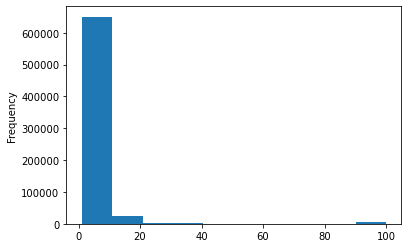

In [40]:
authors_df.groupby('work_id').count()['author_id'].plot(kind='hist');

In [41]:
cite_g = ig.Graph.DataFrame(all_refs)

In [42]:
print(f'n = {cite_g.vcount():,} m = {cite_g.ecount():,}')

n = 1,720,217 m = 7,701,839


In [44]:
cite_g.vs[-1]

igraph.Vertex(<igraph.Graph object at 0x2b929631e310>, 1720216, {'name': 'https://openalex.org/W999972508'})

In [49]:
clusters = cite_g.clusters(mode='weak')

In [50]:
print(clusters.summary())

Clustering with 1720217 elements and 906 clusters


In [54]:
clusters.giant().summary(verbosity=0)

'IGRAPH DN-- 1717565 7700063 -- \n+ attr: name (v)'

In [59]:
sizes = clusters.sizes()

In [61]:
sorted(sizes, reverse=True)[: 5]

[1717565, 99, 37, 27, 24]

In [63]:
7700063 / cite_g.ecount()

0.9997694057224514

In [64]:
aps_cite_g = ig.Graph.DataFrame(only_aps_refs)
print(aps_cite_g.summary(verbosity=0))

IGRAPH DN-- 498095 3162282 -- 
+ attr: name (v)


In [66]:
clusters = aps_cite_g.clusters(mode='weak')
print(clusters.summary())
print(clusters.giant().summary(verbosity=0))

Clustering with 498095 elements and 605 clusters
IGRAPH DN-- 496506 3161247 -- 
+ attr: name (v)


In [67]:
sorted(clusters.sizes(), reverse=True)[: 5]

[496506, 16, 10, 9, 9]

In [69]:
3161247 / aps_cite_g.ecount()

0.9996727047113445